# Первичный анализ набора данных
**Датасет:** Kickstarter Projects (ks-projects-201801.csv).  
**Задача:** бинарная классификация (соберёт проект нужную сумму или нет).


## 1 Загрузка данных и библиотек

In [1]:
import numpy as np               # численные операции (логарифм, бесконечность для границ интервалов)
import pandas as pd              # таблицы: загрузка, фильтрация, группировки
import matplotlib.pyplot as plt  # графики

In [2]:
# Загружаем датасет; столбцы launched и deadline сразу читаем как даты,
# чтобы потом можно было вычитать их друг из друга и брать год/месяц
df = pd.read_csv("ks-projects-201801.csv",
                 parse_dates=["launched", "deadline"])
df.head()  # первые 5 строк, чтобы посмотреть, как выглядят данные

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


## 2 Общая информация


In [3]:
df.shape  # (число строк, число столбцов)

(378661, 15)

In [4]:
df.columns  # названия всех столбцов

Index(['ID', 'name', 'category', 'main_category', 'currency', 'deadline',
       'goal', 'launched', 'pledged', 'state', 'backers', 'country',
       'usd pledged', 'usd_pledged_real', 'usd_goal_real'],
      dtype='object')

In [5]:
df.info()  # тип каждого столбца и число непустых значений

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 378661 entries, 0 to 378660
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   ID                378661 non-null  int64         
 1   name              378657 non-null  object        
 2   category          378661 non-null  object        
 3   main_category     378661 non-null  object        
 4   currency          378661 non-null  object        
 5   deadline          378661 non-null  datetime64[ns]
 6   goal              378661 non-null  float64       
 7   launched          378661 non-null  datetime64[ns]
 8   pledged           378661 non-null  float64       
 9   state             378661 non-null  object        
 10  backers           378661 non-null  int64         
 11  country           378661 non-null  object        
 12  usd pledged       374864 non-null  float64       
 13  usd_pledged_real  378661 non-null  float64       
 14  usd_

In [6]:
df.describe()  # среднее, медиана, квартили, минимум и максимум

,ID,deadline,goal,launched,pledged,backers,usd pledged,usd_pledged_real,usd_goal_real
count,3.786610e+05,378661,3.786610e+05,378661,3.786610e+05,378661.000000,3.748640e+05,3.786610e+05,3.786610e+05
mean,1.074731e+09,2014-11-01 16:04:27.950488832,4.908079e+04,2014-09-28 18:06:17.416520448,9.682979e+03,105.617476,7.036729e+03,9.058924e+03,4.545440e+04
min,5.971000e+03,2009-05-03 00:00:00,1.000000e-02,1970-01-01 01:00:00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,1.000000e-02
25%,5.382635e+08,2013-06-08 00:00:00,2.000000e+03,2013-05-07 22:14:27,3.000000e+01,2.000000,1.698000e+01,3.100000e+01,2.000000e+03
50%,1.075276e+09,2015-01-14 00:00:00,5.200000e+03,2014-12-10 03:23:41,6.200000e+02,12.000000,3.947200e+02,6.243300e+02,5.500000e+03
75%,1.610149e+09,2016-04-28 00:00:00,1.600000e+04,2016-03-24 10:21:09,4.076000e+03,56.000000,3.034090e+03,4.050000e+03,1.550000e+04
max,2.147476e+09,2018-03-03 00:00:00,1.000000e+08,2018-01-02 15:02:31,2.033899e+07,219382.000000,2.033899e+07,2.033899e+07,1.663614e+08
std,6.190862e+08,NaN,1.183391e+06,NaN,9.563601e+04,907.185035,7.863975e+04,9.097334e+04,1.152950e+06


In [7]:
df.describe(include="object")  # для категориальных: число уникальных и самое частое значение

,name,category,main_category,currency,state,country
count,378657,378661,378661,378661,378661,378661
unique,375764,159,15,14,6,23
top,New EP/Music Development,Product Design,Film & Video,USD,failed,US
freq,41,22314,63585,295365,197719,292627


## 3 Пропущенные значения

In [8]:
df.isna().sum()  # количество пропусков по столбцам

ID                     0
name                   4
category               0
main_category          0
currency               0
deadline               0
goal                   0
launched               0
pledged                0
state                  0
backers                0
country                0
usd pledged         3797
usd_pledged_real       0
usd_goal_real          0
dtype: int64

In [9]:
(df.isna().mean() * 100).round(2)  # доля пропусков в процентах

ID                  0.0
name                0.0
category            0.0
main_category       0.0
currency            0.0
deadline            0.0
goal                0.0
launched            0.0
pledged             0.0
state               0.0
backers             0.0
country             0.0
usd pledged         1.0
usd_pledged_real    0.0
usd_goal_real       0.0
dtype: float64

## 4 Дубликаты

In [10]:
df.duplicated().sum()  # число полных копий сверх первого вхождения

0

In [11]:
df["ID"].duplicated().sum()  # проверка, что идентификатор проекта уникален

0

In [12]:
df["name"].duplicated().sum()  # одинаковые названия проектов (перезапуски кампаний)

2896

## 5 Уникальные значения и константные признаки

In [13]:
df.nunique()  # число уникальных непустых значений каждого столбца

ID                  378661
name                375764
category               159
main_category           15
currency                14
deadline              3164
goal                  8353
launched            378089
pledged              62130
state                    6
backers               3963
country                 23
usd pledged          95455
usd_pledged_real    106065
usd_goal_real        50339
dtype: int64

In [14]:
unique_counts = df.nunique()
unique_counts[unique_counts <= 1]  # столбцы с одним значением или без значений

Series([], dtype: int64)

In [15]:
# Топ-10 самых частых значений для основных категориальных признаков
for col in ["main_category", "country", "currency"]:
    print(col)
    print(df[col].value_counts().head(10))
    print()

main_category
main_category
Film & Video    63585
Music           51918
Publishing      39874
Games           35231
Technology      32569
Design          30070
Art             28153
Food            24602
Fashion         22816
Theater         10913
Name: count, dtype: int64

country
country
US      292627
GB       33672
CA       14756
AU        7839
DE        4171
N,0"      3797
FR        2939
IT        2878
NL        2868
ES        2276
Name: count, dtype: int64

currency
currency
USD    295365
GBP     34132
EUR     17405
CAD     14962
AUD      7950
SEK      1788
MXN      1752
NZD      1475
DKK      1129
CHF       768
Name: count, dtype: int64



## 6 Целевая переменная и баланс классов

In [16]:
df["state"].value_counts(dropna=False)  # количество объектов, включая пропуски

state
failed        197719
successful    133956
canceled       38779
undefined       3562
live            2799
suspended       1846
Name: count, dtype: int64

In [17]:
# Однозначный итог есть только у successful и failed.
# canceled автор закрыл сам, suspended заблокировала платформа,
# live ещё идёт, undefined - ошибка выгрузки. Эти строки убираем.
df = df[df["state"].isin(["successful", "failed"])].copy()
# Целевая переменная: 1 - проект собрал сумму, 0 - не собрал
df["target"] = (df["state"] == "successful").astype(int)
df.shape  # сколько строк осталось после фильтрации

(331675, 16)

In [18]:
(df["target"].value_counts(normalize=True) * 100).round(2)  # доли классов

target
0    59.61
1    40.39
Name: proportion, dtype: float64

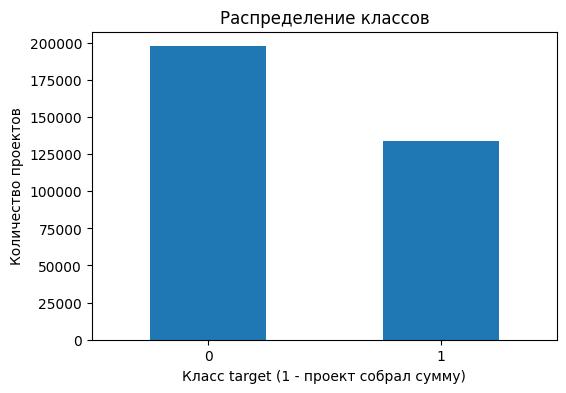

In [19]:
# Столбчатая диаграмма: сколько проектов в каждом классе
df["target"].value_counts().plot(kind="bar", figsize=(6, 4))
plt.title("Распределение классов")
plt.xlabel("Класс target (1 - проект собрал сумму)")
plt.ylabel("Количество проектов")
plt.xticks(rotation=0)  # подписи по горизонтали, без наклона
plt.show()

## 7 Распределения числовых признаков
Все числовые признаки здесь - денежные суммы и число спонсоров. У них огромный разброс:
большинство проектов маленькие, а единицы - на миллионы долларов.

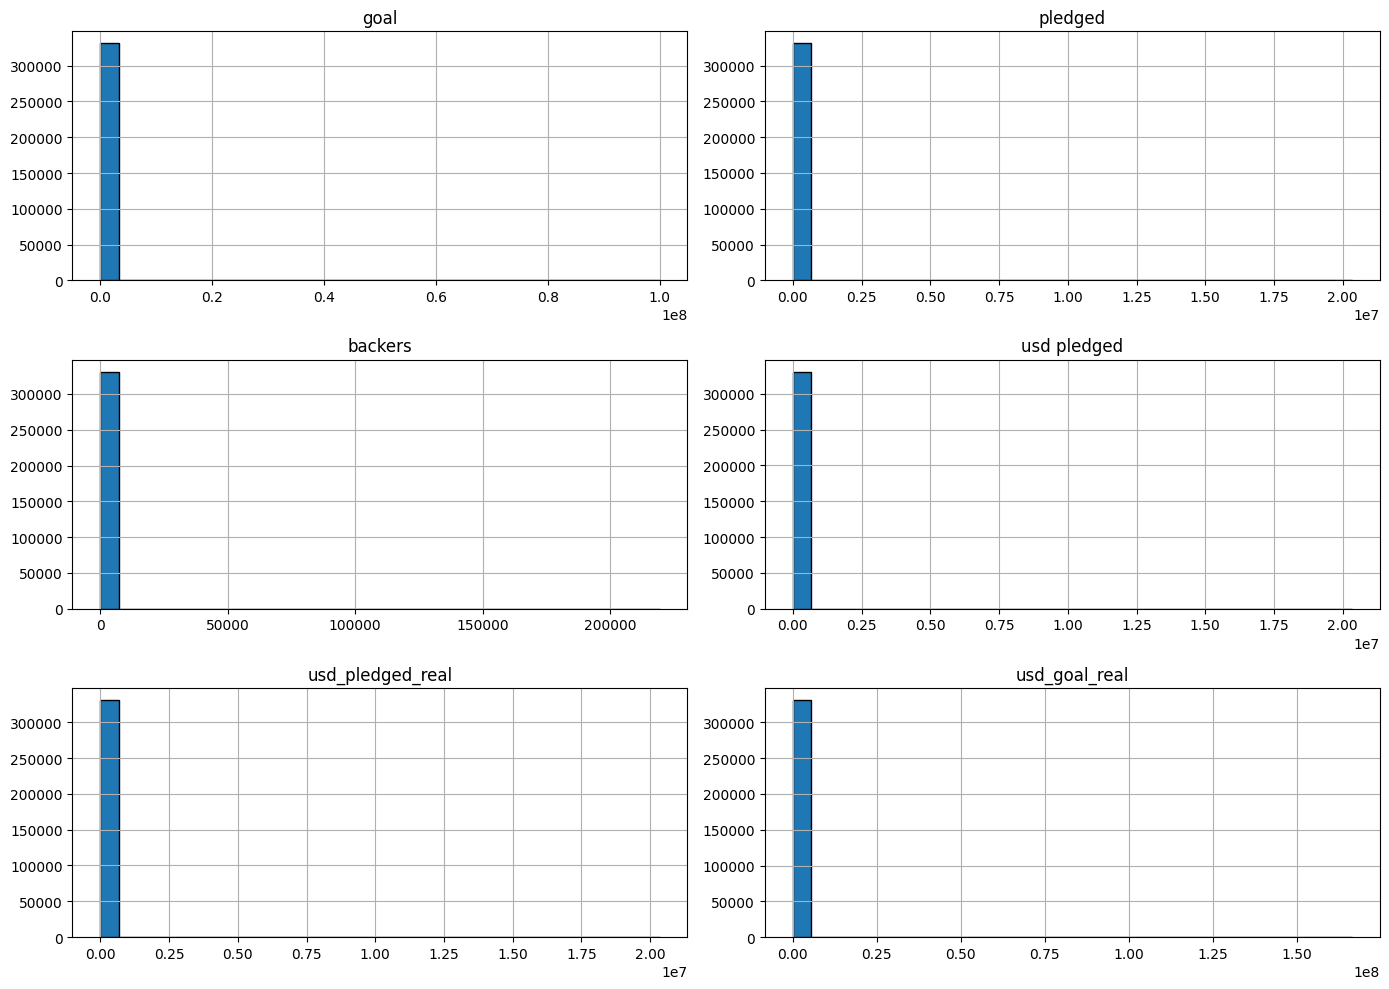

In [20]:
# Гистограммы всех числовых признаков в обычном масштабе
numeric_df = df.select_dtypes(include="number")  # только числовые столбцы
# target и ID не признаки: target - ответ, ID - просто номер проекта
features = numeric_df.drop(columns=["target", "ID"], errors="ignore")
features.hist(bins=30, figsize=(14, 10), edgecolor="black")
plt.tight_layout()  # чтобы подписи графиков не наезжали друг на друга
plt.show()

In [21]:
# Какая доля проектов попала в первый из 30 бинов каждой гистограммы выше
first_bin_share = {}
for col in features.columns:
    counts, edges = np.histogram(features[col].dropna(), bins=30)  # то же разбиение, что у hist
    first_bin_share[col] = round(counts[0] / counts.sum() * 100, 2)
pd.Series(first_bin_share, name="% в первом бине")

goal                99.90
pledged             99.85
backers             99.87
usd pledged         99.91
usd_pledged_real    99.87
usd_goal_real       99.94
Name: % в первом бине, dtype: float64

Почти все проекты (около 99.9%) попадают в первый бин: из-за нескольких гигантских
значений шкала растягивается до сотен миллионов, и форму распределения не видно.
Поэтому дальше смотрим признаки в логарифмическом масштабе.

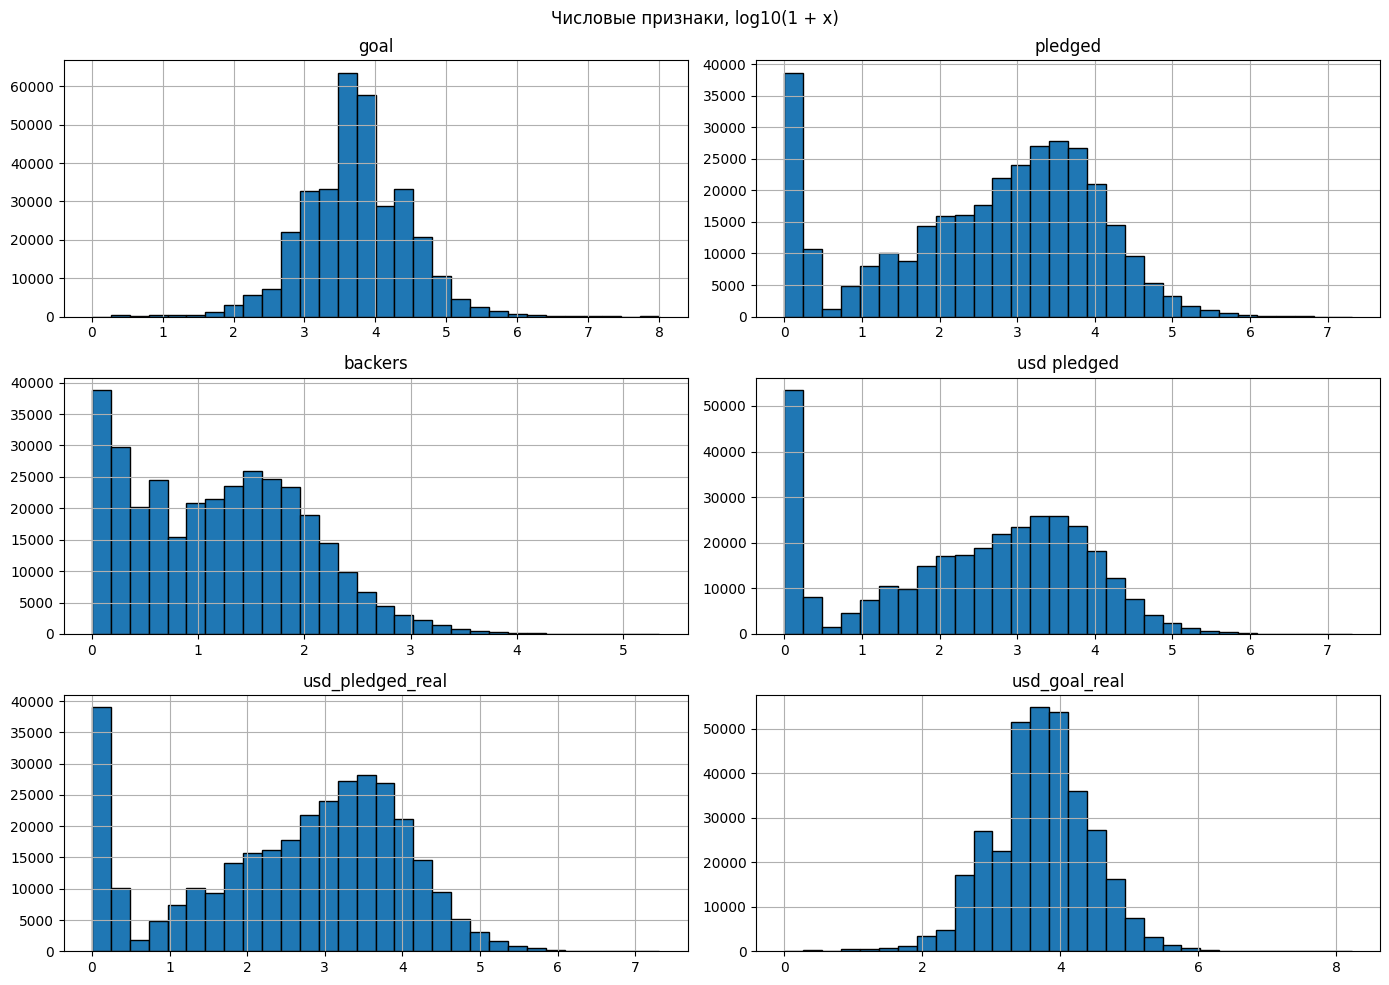

In [22]:
# Те же гистограммы, но по log10(1 + x).
# Единица добавляется, потому что у pledged и backers есть нули, а log10(0) не определён.
# Значение 2 на оси - это около 100, 3 - около 1 000, 4 - около 10 000 и т.д.
np.log10(features + 1).hist(bins=30, figsize=(14, 10), edgecolor="black")
plt.suptitle("Числовые признаки, log10(1 + x)")
plt.tight_layout()
plt.show()

In [23]:
# Распределение по бинам в числах: сколько проектов попало в каждый интервал значений.
# Интервалы растут в 10 раз, как деления на логарифмической шкале.
bin_edges = [-np.inf, 0, 10, 100, 1_000, 10_000, 100_000, 1_000_000, np.inf]
bin_labels = ["0", "до 10", "10-100", "100-1 тыс", "1-10 тыс",
              "10-100 тыс", "100 тыс-1 млн", "больше 1 млн"]
bin_table = pd.DataFrame({
    col: pd.cut(features[col], bins=bin_edges, labels=bin_labels).value_counts(sort=False)
    for col in features.columns
})
bin_table  # строки - интервалы, столбцы - признаки, в ячейках - число проектов

,goal,pledged,backers,usd pledged,usd_pledged_real,usd_goal_real
0,0,38656,38847,53315,38656,0
до 10,1025,20994,110768,18160,20505,951
10-100,4757,41305,124670,43710,41705,4323
100-1 тыс,52337,74011,51380,77257,74164,50207
1-10 тыс,170386,106964,5761,98954,107749,171664
10-100 тыс,92965,44491,246,36532,44089,94774
100 тыс-1 млн,9311,4934,3,3348,4534,8916
больше 1 млн,894,320,0,189,273,840


In [24]:
# То же самое в процентах от числа проектов (пропуски в usd pledged не учитываются)
(bin_table / bin_table.sum() * 100).round(2)

,goal,pledged,backers,usd pledged,usd_pledged_real,usd_goal_real
0,0.00,11.65,11.71,16.08,11.65,0.00
до 10,0.31,6.33,33.40,5.48,6.18,0.29
10-100,1.43,12.45,37.59,13.19,12.57,1.30
100-1 тыс,15.78,22.31,15.49,23.31,22.36,15.14
1-10 тыс,51.37,32.25,1.74,29.85,32.49,51.76
10-100 тыс,28.03,13.41,0.07,11.02,13.29,28.57
100 тыс-1 млн,2.81,1.49,0.00,1.01,1.37,2.69
больше 1 млн,0.27,0.10,0.00,0.06,0.08,0.25


**Выводы по распределениям:**
- все признаки сильно скошены вправо: медиана намного меньше среднего, есть редкие огромные значения;
- в логарифмическом масштабе распределения становятся похожими на нормальные, поэтому для модели
  цель сбора берём как `log_goal = log10(usd_goal_real)` (раздел 12);
- у pledged, usd_pledged_real и backers около 12% нулей - проекты, которые не собрали ни доллара;
- goal и pledged указаны в валюте проекта, а usd_* - уже в долларах, поэтому сравнивать между
  собой корректно только usd-столбцы.

## 8 Boxplot одного признака
Для другого признака достаточно изменить значение `column`.

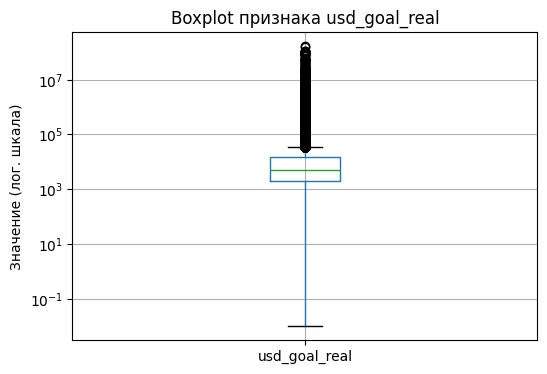

In [25]:
column = "usd_goal_real"  # признак для boxplot
df.boxplot(column=column, figsize=(6, 4))
plt.yscale("log")  # логарифмическая шкала, иначе из-за выбросов ящик сплющивается в линию
plt.title(f"Boxplot признака {column}")
plt.ylabel("Значение (лог. шкала)")
plt.show()

Линия внутри ящика — медиана, ящик охватывает центральные 50% значений. Отдельные точки за усами — потенциальные выбросы

## 9 Проверка качества конкретных столбцов

In [26]:
# Ошибочные даты запуска: в выгрузке есть нулевая дата 1970-01-01
# (считаем уже после фильтрации по state; по всему датасету таких 7)
(df["launched"].dt.year == 1970).sum()

0

In [27]:
# Ошибка выгрузки: вместо кода страны записан мусор
# (считаем уже после фильтрации по state; по всему датасету таких 3797)
(df["country"] == 'N,0"').sum()

210

In [28]:
# Экстремальные цели сбора
print("Цель больше 1 млн USD:", (df["usd_goal_real"] > 1_000_000).sum())
print("Цель меньше 10 USD:", (df["usd_goal_real"] < 10).sum())
print("Минимум и максимум:", df["usd_goal_real"].min(), df["usd_goal_real"].max())

Цель больше 1 млн USD: 840
Цель меньше 10 USD: 643
Минимум и максимум: 0.01 166361390.71


## 10 Связь признаков с целевой переменной

In [29]:
df.groupby("main_category")["target"].mean().sort_values().round(3)  # доля успешных проектов по категориям

main_category
Technology      0.238
Journalism      0.244
Crafts          0.271
Food            0.276
Fashion         0.283
Photography     0.341
Publishing      0.347
Design          0.416
Film & Video    0.418
Games           0.439
Art             0.449
Music           0.527
Comics          0.591
Theater         0.638
Dance           0.654
Name: target, dtype: float64

In [30]:
# Делим цель сбора на интервалы (до 1000, 1000-5000, ... , больше 100 000 USD)
bins = [0, 1000, 5000, 20000, 100000, np.inf]
df["goal_bin"] = pd.cut(df["usd_goal_real"], bins)
# Для каждого интервала: доля успешных проектов (mean) и число проектов (count)
df.groupby("goal_bin", observed=True)["target"].agg(["mean", "count"]).round(3)

,mean,count
goal_bin,,
"(0.0, 1000.0]",0.538,55481
"(1000.0, 5000.0]",0.466,112438
"(5000.0, 20000.0]",0.378,101976
"(20000.0, 100000.0]",0.240,52024
"(100000.0, inf]",0.075,9756


## 11 Краткий итог аудита

In [31]:
# Сводка по данным после фильтрации
print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns))
print("Пропущенных ячеек:", df.isna().sum().sum())
print("Полных копий:", df.duplicated().sum())
print("Доля успешных проектов:", round(df["target"].mean(), 3))

Количество строк: 331675
Количество столбцов: 17
Пропущенных ячеек: 213


Полных копий: 0
Доля успешных проектов: 0.404


## 12 Предобработка данных

In [32]:
# Утечка целевой переменной: эти столбцы известны только после окончания кампании
# и фактически определяют итог, поэтому в модель они не идут.
leak_cols = ["pledged", "usd pledged", "usd_pledged_real", "backers", "state"]
df = df.drop(columns=leak_cols)

In [33]:
# Чистка ошибочных значений
df = df[df["launched"].dt.year > 1970]  # убираем нулевые даты запуска
df = df[df["country"] != 'N,0"']        # убираем строки с мусором вместо страны

In [34]:
# Признаки, известные автору до запуска кампании
df["duration_days"] = (df["deadline"] - df["launched"].dt.normalize()).dt.days  # длительность кампании в днях
df["launch_month"] = df["launched"].dt.month      # месяц запуска (1-12)
df["launch_weekday"] = df["launched"].dt.weekday  # день недели запуска (0 - понедельник)
df["launch_year"] = df["launched"].dt.year        # год запуска, нужен для разбиения на train/test
df["log_goal"] = np.log10(df["usd_goal_real"])    # логарифм цели сбора, сглаживает огромный разброс
df["name_len"] = df["name"].fillna("").str.len()  # длина названия в символах (пустые названия -> 0)
df["name_words"] = df["name"].fillna("").str.split().str.len()  # число слов в названии
df.head()

,ID,name,category,main_category,currency,deadline,goal,launched,country,usd_goal_real,target,goal_bin,duration_days,launch_month,launch_weekday,launch_year,log_goal,name_len,name_words
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,GB,1533.95,0,"(1000.0, 5000.0]",59,8,1,2015,3.185811,31,6
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,US,30000.00,0,"(20000.0, 100000.0]",60,9,5,2017,4.477121,45,8
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,US,45000.00,0,"(20000.0, 100000.0]",45,1,5,2013,4.653213,14,3
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,US,5000.00,0,"(1000.0, 5000.0]",30,3,5,2012,3.698970,49,7
5,1000014025,Monarch Espresso Bar,Restaurants,Food,USD,2016-04-01,50000.0,2016-02-26 13:38:27,US,50000.00,1,"(20000.0, 100000.0]",35,2,4,2016,4.698970,20,3


In [35]:
# Итоговый набор признаков для модели
feature_cols = ["main_category", "category", "country", "currency",
                "log_goal", "duration_days", "launch_month",
                "launch_weekday", "name_len", "name_words"]
X = df[feature_cols]  # признаки
y = df["target"]      # ответ
X.shape, y.shape

((331465, 10), (331465,))

In [36]:
# Разбиение по времени: обучение на 2009-2016, тест на 2017
# (так модель проверяется на "будущих" проектах, которых не видела при обучении)
train_mask = df["launch_year"] <= 2016  # True - строка идёт в обучение, False - в тест
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[~train_mask], y[~train_mask]  # ~ - логическое "не"
print("Обучение:", X_train.shape, "Тест:", X_test.shape)

Обучение: (288046, 10) Тест: (43419, 10)
